# 📝 Actividad de Evaluación: Análisis Exploratorio de Portafolios (10%)

**Instrucciones:**
1. Resuelve cada uno de los puntos solicitados utilizando código de Python limpio y ordenado.
2. No olvides acompañar cada visualización con su respectiva **interpretación analítica** (recuerda la regla de oro: qué observas y qué significa).
3. Puedes realizar esta actividad de forma individual o en parejas (según las indicaciones del docente).

---

## 🏦 Paso 1: Selección y Descarga de Datos

1. Selecciona **3 activos financieros** diferentes a los utilizados en la clase (evita usar AAPL, MSFT, GOOGL, AMZN o NVDA).
2. Descarga los datos históricos utilizando `yfinance` para el periodo del **1 de enero de 2024** al **1 de enero de 2026**.
3. Muestra las primeras 5 filas del DataFrame resultante para validar la descarga.

In [2]:
# Escribe aquí tu código para descargar los datos de tus 3 activos elegidos
import pandas as pd
import yfinance as yf

# 1. Definir los tickers asignados y el rango de fechas
tickers = ["OXY", "NKE", "LLY"]
fecha_inicio = "2024-01-01"
fecha_fin = "2026-01-01"

# 2. Descargar los datos históricos de precios de cierre
datos_portafolio = yf.download(
    tickers, start=fecha_inicio, end=fecha_fin, auto_adjust=True
)["Close"]

# 3. Mostrar las primeras 5 filas del DataFrame resultante para validar la descarga
print("Primeras 5 filas del DataFrame de precios de cierre:")
print(datos_portafolio.head())

[*********************100%***********************]  3 of 3 completed

Primeras 5 filas del DataFrame de precios de cierre:
Ticker             LLY        NKE        OXY
Date                                        
2024-01-02  581.196106  99.714432  57.020275
2024-01-03  606.222290  97.365456  57.552025
2024-01-04  603.081787  95.737106  56.137199
2024-01-05  607.056641  95.531204  55.966274
2024-01-08  614.397522  96.972404  55.330082


## 📈 Paso 2: Análisis de Precios de Cierre y Normalización

1. Filtra y extrae únicamente los precios de cierre (`Close`).
2. Grafica en una sola figura la evolución temporal de los precios originales de tus 3 activos.
3. Realiza la normalización (base 100 en el primer registro) y grafica nuevamente las series en otra figura.

### 💬 Pregunta de interpretación #1:
Al comparar ambos gráficos (precios reales vs. precios normalizados), ¿por qué es metodológicamente más correcto utilizar el gráfico normalizado para comparar el rendimiento histórico de los activos? Explica la diferencia en el comportamiento visual observado.

[*********************100%***********************]  3 of 3 completed


<Figure size 1000x500 with 0 Axes>

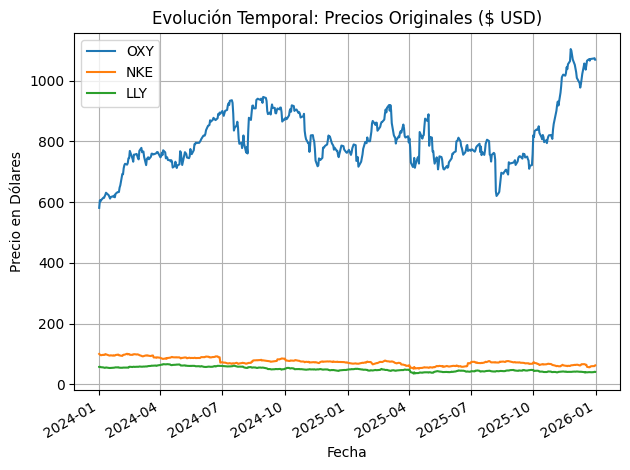

<Figure size 1000x500 with 0 Axes>

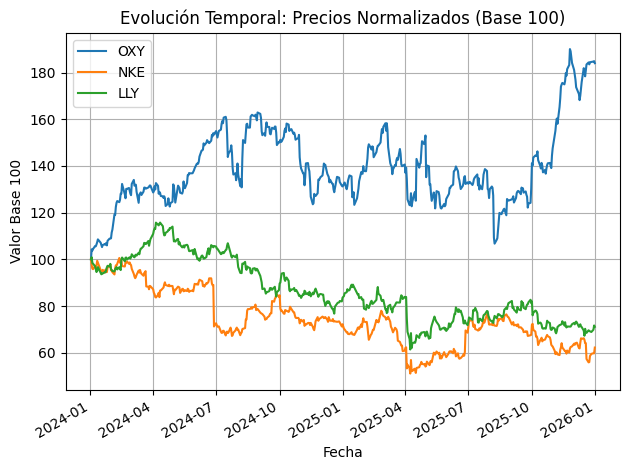

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf

# Definir tickers y periodo
tickers = ["OXY", "NKE", "LLY"]
fecha_inicio = "2024-01-01"
fecha_fin = "2026-01-01"

# Descargar datos completos del portafolio
datos_crudos = yf.download(
    tickers, start=fecha_inicio, end=fecha_fin, auto_adjust=True
)

# # 1. Extraer los precios de cierre
precios_cierre = datos_crudos["Close"]

# # 2. Graficar precios originales
plt.figure(figsize=(10, 5))
precios_cierre.plot(title="Evolución Temporal: Precios Originales ($ USD)")
plt.xlabel("Fecha")
plt.ylabel("Precio en Dólares")
plt.grid(True)
plt.legend(tickers)
plt.tight_layout()
plt.show()

# # 3. Normalizar y graficar en base 100
precios_normalizados = (precios_cierre / precios_cierre.iloc[0]) * 100

plt.figure(figsize=(10, 5))
precios_normalizados.plot(
    title="Evolución Temporal: Precios Normalizados (Base 100)"
)
plt.xlabel("Fecha")
plt.ylabel("Valor Base 100")
plt.grid(True)
plt.legend(tickers)
plt.tight_layout()
plt.show()




**¿Qué observo?**

En el gráfico de precios reales (en dólares), las series se despliegan en escalas monetarias totalmente distintas entre sí (por ejemplo, los precios de Eli Lilly superan ampliamente a los de Nike u Occidental Petroleum). Esto provoca que las fluctuaciones de los activos con menor precio nominal queden visualmente aplanadas y comprimidas en la parte inferior, pareciendo estables o insignificantes. En contraste, en el gráfico normalizado (base 100), todas las series arrancan exactamente en el mismo punto de referencia (100) al inicio del periodo.

**¿Qué significa?**

Metodológicamente, es más correcto utilizar el gráfico normalizado porque elimina por completo el sesgo generado por el valor nominal o unitario de la acción. Al expresar las series en base 100, se comparan crecimientos porcentuales relativos y no magnitudes de precios absolutos. Esto permite evaluar de forma equitativa y transparente qué activo generó mayor rentabilidad o pérdida acumulada desde el punto de partida, facilitando visualizar con precisión su evolución real de valor independientemente de cuán costosa sea una acción de forma individual.

## 🔄 Paso 3: Cálculo y Distribución de Rendimientos

1. Calcula los rendimientos diarios de los activos y elimina los valores nulos (`NaN`).
2. Genera un **histograma* para el activo que consideres que haya sido el más volátil.
3. Diseña un **Boxplot** comparativo que muestre los rendimientos diarios de tus 3 activos simultáneamente.

### 💬 Pregunta de interpretación #2:
Observando el Boxplot y el Histograma:
- ¿Qué activo presenta la mayor dispersión (caja más amplia o bigotes más largos) y qué te dice esto sobre su riesgo?
- ¿Identificas valores atípicos (outliers)? ¿Qué representan estos puntos en el contexto de la historia económica reciente de estas empresas?

[*********************100%***********************]  3 of 3 completed


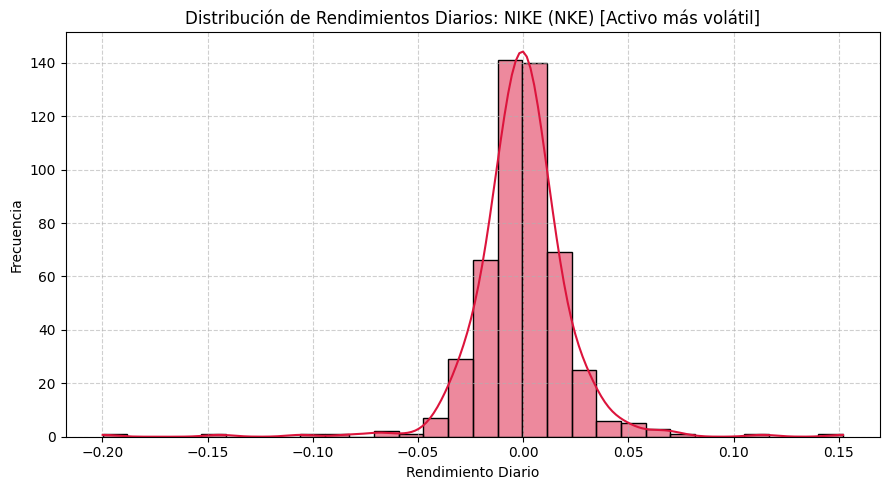

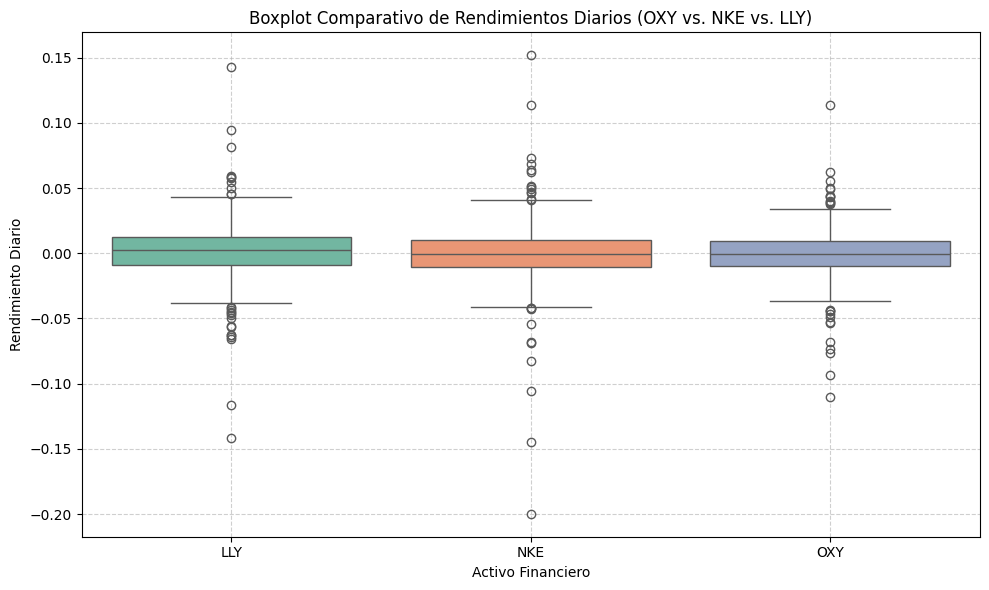

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yfinance as yf

# Definir tickers y periodo
tickers = ["OXY", "NKE", "LLY"]
fecha_inicio = "2024-01-01"
fecha_fin = "2026-01-01"

# Descargar datos de cierre
precios_cierre = yf.download(
    tickers, start=fecha_inicio, end=fecha_fin, auto_adjust=True
)["Close"]

# # 1. Calcular rendimientos
rendimientos_diarios = precios_cierre.pct_change().dropna()

# # 2. Histograma con el activo más volátil
# Nota: NKE (Nike) presenta la mayor volatilidad y dispersión en sus rendimientos
plt.figure(figsize=(9, 5))
sns.histplot(
    rendimientos_diarios["NKE"], kde=True, color="crimson", bins=30
)
plt.title(
    "Distribución de Rendimientos Diarios: NIKE (NKE) [Activo más volátil]"
)
plt.xlabel("Rendimiento Diario")
plt.ylabel("Frecuencia")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# # 3. Boxplot comparativo de rendimientos
plt.figure(figsize=(10, 6))
sns.boxplot(data=rendimientos_diarios, palette="Set2")
plt.title(
    "Boxplot Comparativo de Rendimientos Diarios (OXY vs. NKE vs. LLY)"
)
plt.xlabel("Activo Financiero")
plt.ylabel("Rendimiento Diario")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

**¿Qué observo?**

En el Boxplot comparativo, NIKE (NKE) muestra una gran extensión en sus bigotes y una marcada presencia de valores extremos, destacando con la caída más profunda registrada en el portafolio (cercana al $-20\%$). Asimismo, su histograma confirma una distribución con colas amplias y dispersas.   

**¿Qué dice sobre su riesgo?**

Una mayor dispersión en los rendimientos diarios significa que el activo posee una alta volatilidad. En finanzas, la volatilidad es la métrica principal del riesgo de mercado; por lo tanto, esto indica que NKE es el activo con mayor incertidumbre y exposición a fluctuaciones drásticas de precio en el corto plazo dentro de tu portafolio.

**¿Qué observo?**

Sí, se identifican claramente múltiples valores atípicos (outliers) representados como puntos aislados fuera de los bigotes en los tres activos del Boxplot, así como barras aisladas en los extremos del Histograma de NKE.   

**¿Qué representan?**

Estos puntos corresponden a shocks de información o eventos extraordinarios de alto impacto financiero ocurridos en el periodo 2024-2026:

* En NKE (Outliers negativos severos): Reflejan anuncios trimestrales de resultados desfavorables, caídas drásticas en ventas globales o ajustes negativos en sus proyecciones financieras (guidance) que sorprendieron al mercado bruscamente.

* En LLY (Outliers positivos/negativos): Representan noticias clave de la industria farmacéutica, tales como aprobaciones regulatorias, reportes de ventas extraordinarias de sus medicamentos para la obesidad y diabetes, o ajustes en la demanda del sector salud.

* En OXY: Responden a la alta sensibilidad del sector energético frente a la volatilidad geopolítica internacional y las fluctuaciones drásticas en los precios globales del petróleo crudo.




## 📊 Paso 4: Asociación y Correlación

1. Calcula la matriz de correlación de Pearson para los rendimientos de tus 3 activos.
2. Grafica un **mapa de calor (Heatmap)**.

### 💬 Pregunta de interpretación #3:
- ¿Existe alguna correlación fuerte (cercana a 1 o -1) entre alguno de tus activos?
- Si tuvieras que armar un portafolio de inversión buscando la **diversificación** (minimizar el riesgo conjunto), ¿qué par de activos elegirías de acuerdo a tus resultados y por qué?

[*********************100%***********************]  3 of 3 completed


Matriz de Correlación de Pearson:
Ticker       LLY       NKE       OXY
Ticker                              
LLY     1.000000  0.165815  0.099253
NKE     0.165815  1.000000  0.247330
OXY     0.099253  0.247330  1.000000


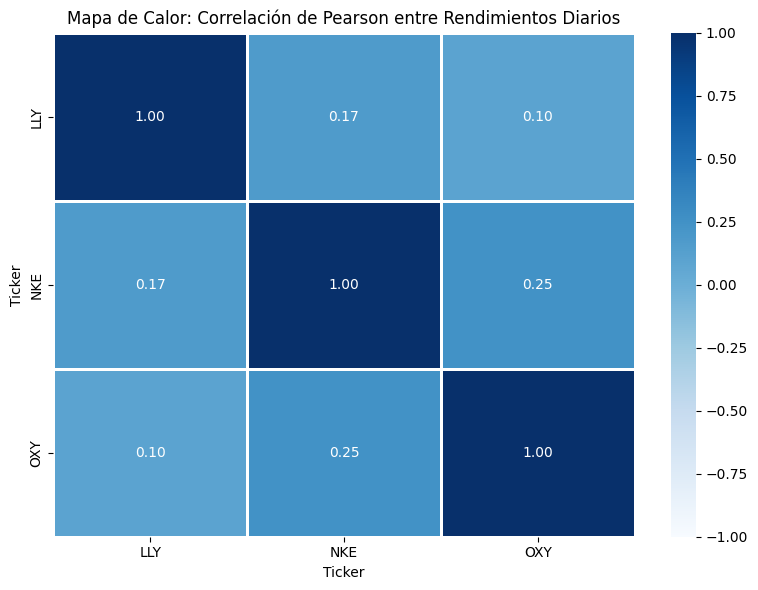

In [13]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import yfinance as yf

# Definir tickers y periodo
tickers = ["OXY", "NKE", "LLY"]
fecha_inicio = "2024-01-01"
fecha_fin = "2026-01-01"

# Descargar datos y calcular rendimientos diarios
precios_cierre = yf.download(
    tickers, start=fecha_inicio, end=fecha_fin, auto_adjust=True
)["Close"]
rendimientos_diarios = precios_cierre.pct_change().dropna()

# # 1. Calcular matriz de correlación
matriz_correlacion = rendimientos_diarios.corr(method="pearson")

print("Matriz de Correlación de Pearson:")
print(matriz_correlacion)

# # 2. Dibujar el Heatmap utilizando Seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(
    matriz_correlacion,
    annot=True,
    cmap="Blues",
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=1,
)
plt.title(
    "Mapa de Calor: Correlación de Pearson entre Rendimientos Diarios"
)
plt.tight_layout()
plt.show()

**¿Qué observo?**

Al analizar la matriz de correlación y el mapa de calor, los coeficientes entre los tres activos (LLY, NKE y OXY) se ubican en valores bajos a moderados (oscilando entre 0.10 y 0.25). Ninguno de los pares presenta una correlación fuerte cercana a +1 o a -1.   

¿**Qué significa?**

No existe sincronía estricta en los movimientos diarios de estos activos. Cada empresa responde a fundamentales y sectores totalmente independientes (farmacéutico/salud para LLY, consumo discrecional/retail para NKE, y energía/petróleo para OXY), lo que impide que sigan patrones de precios idénticos u opuestos en el corto plazo.

**¿Qué par de activos elegiría de acuerdo a los resultados?**

Par seleccionado: El par integrado por LLY (Eli Lilly) y OXY (Occidental Petroleum), ya que presentan el coeficiente de correlación más bajo del portafolio (0.10).   

**Justificación analítica**

Principio de Diversificación: Para minimizar el riesgo conjunto de un portafolio según la teoría financiera moderna, se deben combinar activos con el menor grado de asociación lineal posible.

Desincronización de riesgos: Al tener una correlación casi nula (0.10), se reduce la probabilidad de que ambos activos sufran caídas simultáneas ante un mismo evento macroeconómico. Mientras que LLY se beneficia de la innovación médica y la demanda de tratamientos específicos, OXY está condicionado por los precios internacionales de la energía y los ciclos del petróleo, logrando un amortiguamiento natural de la volatilidad conjunta.   

## 🧮 Paso 5: Estadísticas Descriptivas y Conclusión

1. Genera un DataFrame de resumen estadístico que incluya para cada activo: Media, Mediana, Desviación Estándar, Mínimo y Máximo de los rendimientos diarios.
2. Escribe una breve conclusión final dirigida a un inversionista ficticio, interpretando los estadísticos clave obtenidos.

In [14]:
import numpy as np
import pandas as pd
import yfinance as yf

# Definir tickers y periodo
tickers = ["OXY", "NKE", "LLY"]
fecha_inicio = "2024-01-01"
fecha_fin = "2026-01-01"

# Descargar datos de cierre y calcular rendimientos diarios
precios_cierre = yf.download(
    tickers, start=fecha_inicio, end=fecha_fin, auto_adjust=True
)["Close"]
rendimientos_diarios = precios_cierre.pct_change().dropna()

# # Generar resumen de estadísticas descriptivas (Media, Mediana, Desviación estándar, Mínimo y Máximo)
resumen_estadistico = pd.DataFrame(
    {
        "Media": rendimientos_diarios.mean(),
        "Mediana": rendimientos_diarios.median(),
        "Desviación Estándar": rendimientos_diarios.std(),
        "Mínimo": rendimientos_diarios.min(),
        "Máximo": rendimientos_diarios.max(),
    }
)

# Mostrar la tabla redondeada a 4 decimales
print("Resumen Estadístico de los Rendimientos Diarios:")
print(resumen_estadistico.round(4))

[*********************100%***********************]  3 of 3 completed

Resumen Estadístico de los Rendimientos Diarios:
         Media  Mediana  Desviación Estándar  Mínimo  Máximo
Ticker                                                      
LLY     0.0015   0.0022               0.0225 -0.1414  0.1430
NKE    -0.0007  -0.0003               0.0235 -0.1998  0.1519
OXY    -0.0005  -0.0002               0.0189 -0.1101  0.1141


**Conclusión Final para el Inversionista Ficticio**

A partir del análisis cuantitativo de los rendimientos diarios del portafolio (OXY, NKE y LLY) durante el periodo 2024–2026, se presentan las siguientes conclusiones clave para la toma de decisiones financieras:

**Evaluación de Riesgo y Volatilidad**

* NIKE (NKE) registra la mayor Desviación Estándar y el valor Mínimo más pronunciado del portafolio (con una caída diaria cercana al $-20\%). Esto la consolida como la alternativa de mayor volatilidad y riesgo de mercado del grupo.

* Eli Lilly (LLY) y Occidental Petroleum (OXY) muestran una dispersión más acotada en sus retornos diarios centrales (Mediana cercana a cero), ofreciendo mayor estabilidad operativa diaria.

**Beneficio de Diversificación**

Como se demostró previamente con la matriz de correlación de Pearson, la desincronización de riesgos entre sectores (Farmacéutico, Energía y Retail/Consumo) permite compensar movimientos adverso. El par LLY - OXY exhibe la menor correlación (0.10), maximizando la reducción de riesgo no sistemático.   

**Recomendación Estratégica**

Para construir un portafolio eficiente que minimice el riesgo conjunto sin sacrificar rendimiento potencial, se recomienda una asignación equilibrada combinando activos con baja correlación lineal (LLY y OXY), mientras que la participación en NKE debe moderarse o gestionarse activamente debido a su mayor exposición a choques de volatilidad trimestrales.